In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import os
import glob
import shutil
import geopandas as gpd

import xarray as xr
import numpy as np
#from pyhomogenize import open_xrdataset
import seaborn as sns
#
import matplotlib as mpl
import matplotlib.pyplot as plt
import cftime
import xesmf as xe
import cordex as cx

In [3]:
from colors_indices import colorsteps_diff, colorsteps_absolute, colorsteps_exposure
from plotting_tools_africa import plot_absolut
from plotting_shape_file import min_max_levels, mask_and_save, maskout_country
from regrid_afr22 import regrid_ensemble_median

In [4]:
# The data needs to be regridded to the AFR-22 domain.
# Target Grid::
dm=cx.cordex_domain('AFR-22', bounds=True)

In [5]:
# Directory input data, calculated compound events
datadir='/work/ch0636/g300047/cicles/compound-events/results'

#testfile=datadir+'/compev_SU40_du3_TR26_du3_AFR-22_MPI-M-MPI-ESM-LR_rcp85_r1i1p1_CLMcom-KIT-CCLM5-0-15_v1_day_GERICS_2069-2098.nc'
#comeve_ds=xr.open_dataset(testfile, decode_times=False)

In [6]:
# Input shapefile:
# Admin regions
# select country and correct shape file
country='Burkina_Faso'

adm_reg_dir='/work/ch0636/g300047/cicles/regions/WASCAL/WASCAL_Country'
admfiles = ['Togo.shp', "Côte d'Ivoire.shp",'Burkina Faso.shp']

# Select admit files
adm_shapefile =os.path.join(adm_reg_dir, admfiles[2])
shpfile_country=gpd.read_file(adm_shapefile)


In [7]:
# Make desision what you want to plot: 
#var_pattern='SU40_du3_TR26_du3'
#title="Ensemble Median of Concurrent Heatwave [Tmax>40°C] and Tropical Night [Tmin>26°C]\nEvents Lasting at Least 3 Days"
var_pattern='SU35_du3_DD_du5'
title="Ensemble Median of Concurrent Heatwave [Tmax>35°C] and Dry Days [RR<1mm/day]\nEvents Lasting at Least 3 and 5 Days"
#no:
#var_pattern='SU35_du3_R20mm_du1'
#title="Ensemble Median of Concurrent Heatwave [Tmax>35°C] and Heavy Precipitation Event [RR>20mm/day]\nEvents Lasting at Least 3 and 1 Days"
#var_pattern='SU40_du3_DD_du5'
#title="Ensemble Median of Concurrent Heatwave [Tmax>40°C] and Dry Days [RR<1mm/day]\nEvents Lasting at Least 3 and 5 Days"
#var_pattern='SU40_du3_R20mm_du1'
#title="Ensemble Median of Concurrent Heatwave [Tmax>40°C] and Heavy Precipitation Event [RR>20mm/day]\nEvents Lasting at Least 3 and 1 Days"
#var_pattern='SU40_du3_R50mm_du1'
#title="Ensemble Median of Concurrent Heatwave [Tmax>40°C] and Heavy Precipitation Event [RR>50mm/day]\nEvents Lasting at Least 3 and 1 Days"
#var_pattern='SU40_du3_TR_du3'
#title="Ensemble Median of Concurrent Heatwave [Tmax>40°C] and Tropical Night [Tmin>20°C]\nEvents Lasting at Least 3 Days"

In [9]:
# Example file name:
# compev_SU40_du3_TR26_du3_AFR-22_MPI-M-MPI-ESM-LR_rcp85_r1i1p1_GERICS-REMO2015_v1_day_GERICS_1991-2020.nc
# Loop over RCPs and time slices, regrid and compute ensemble median

weights_dir=os.path.join(datadir,'weights')
whole_ensemble_regridded=[]

for rcp in ['rcp26', 'rcp85']:
    print(f'rcp: {rcp}')
    for time_slice in ['1991-2020', '2031-2060', '2069-2098']:
        print(f'  time_slice: {time_slice}')
        pattern=f'compev_{var_pattern}*{rcp}*{time_slice}.nc'
        inputfiles=glob.glob(os.path.join(datadir,pattern))
        print(inputfiles)
        # Regrid and compute ensemble median for the variable 'ev_coin_sdu'
        outfile=f'ENSEMBLE/ev_coin_sdu_median_{var_pattern}_{rcp}_{time_slice}.nc'
        name=f'ev_coin_sdu_median_{rcp}_{time_slice}'
        name=regrid_ensemble_median(inputfiles,dm, weights_dir, weightvar='ev_coin_sdu')
        outpath = os.path.join(datadir, outfile)
        name.to_dataset().to_netcdf(
            outpath,
            encoding={'ev_coin_sdu_median': {'zlib': True, 'complevel': 4}}
        )
        whole_ensemble_regridded.append(name)
        print(len(inputfiles))


rcp: rcp26
  time_slice: 1991-2020
['/work/ch0636/g300047/cicles/compound-events/results/compev_SU35_du3_DD_du5_AFR-22_MPI-M-MPI-ESM-LR_rcp26_r1i1p1_CLMcom-KIT-CCLM5-0-15_v1_day_GERICS_1991-2020.nc', '/work/ch0636/g300047/cicles/compound-events/results/compev_SU35_du3_DD_du5_AFR-22_MOHC-HadGEM2-ES_rcp26_r1i1p1_GERICS-REMO2015_v1_day_GERICS_1991-2020.nc', '/work/ch0636/g300047/cicles/compound-events/results/compev_SU35_du3_DD_du5_AFR-22_NCC-NorESM1-M_rcp26_r1i1p1_GERICS-REMO2015_v1_day_GERICS_1991-2020.nc', '/work/ch0636/g300047/cicles/compound-events/results/compev_SU35_du3_DD_du5_AFR-22_NCC-NorESM1-MNCC-NorESM1-M_rcp26_r1i1p1_ICTP-RegCM4-7-0ICTP-RegCM4-7_v0_day_GERICS_1991-2020.nc', '/work/ch0636/g300047/cicles/compound-events/results/compev_SU35_du3_DD_du5_AFR-22_MPI-M-MPI-ESM-LR_rcp26_r1i1p1_ICTP-RegCM4-7-0_v0_day_GERICS_1991-2020.nc', '/work/ch0636/g300047/cicles/compound-events/results/compev_SU35_du3_DD_du5_AFR-22_NCC-NorESM1-M_rcp26_r1i1p1_CLMcom-KIT-CCLM5-0-15_v1_day_GERICS_199

In [8]:
sims_rcp26 = glob.glob(datadir+'/ENSEMBLE/ev_coin_sdu_median_'+var_pattern+'_rcp26_*'+'.nc' )
# Sort the files to ensure correct order
sims_rcp26.sort()
sims_rcp26
sims_rcp85 = glob.glob(datadir+'/ENSEMBLE/ev_coin_sdu_median_'+var_pattern+'_rcp85_*'+'.nc' )
# Sort the files to ensure correct order
sims_rcp85.sort()
sims_rcp85

['/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/ev_coin_sdu_median_SU35_du3_DD_du5_rcp85_1991-2020.nc',
 '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/ev_coin_sdu_median_SU35_du3_DD_du5_rcp85_2031-2060.nc',
 '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/ev_coin_sdu_median_SU35_du3_DD_du5_rcp85_2069-2098.nc']

In [9]:
# plot
plot_dir='/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events'
var='ev_coin_sdu_median'
print('Selected colors, levels for plotting ', var)
color_steps, level_steps = colorsteps_absolute(var)

# mask out only country
sims_rcp26_masked, sims_rcp85_masked = maskout_country(
    sims_rcp26,
    sims_rcp85,
    shpfile_country,
    dm,
    var,
    datadir
)

Selected colors, levels for plotting  ev_coin_sdu_median
Masked files saved:
rcp26: ['/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp26_1991-2020_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp26_2031-2060_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp26_2069-2098_BF_masked.nc']
rcp85: ['/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp85_1991-2020_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp85_2031-2060_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp85_2069-2098_BF_masked.nc']


['/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp26_1991-2020_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp26_2031-2060_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp26_2069-2098_BF_masked.nc']
['/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp85_1991-2020_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp85_2031-2060_BF_masked.nc', '/work/ch0636/g300047/cicles/compound-events/results/ENSEMBLE/masked/ev_coin_sdu_median_SU35_du3_DD_du5_rcp85_2069-2098_BF_masked.nc']
shapefile provided:
adding borders from shapefile
adding borders from shapefile
adding borders from shapefile
adding borders from shapefile
adding borders from shapefile
adding borders fro

/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/HORIZONTAL/plotting_tools_africa.py:600: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0.03, 0.01, 0.97, 0.99])


file is here: /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events/ev_coin_sdu_median_absolut_Burkina_Faso_1200.png
src:  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events/ev_coin_sdu_median_absolut_Burkina_Faso_1200.png
Moving /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events/ev_coin_sdu_median_absolut_Burkina_Faso_1200.png -> /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events/SU35_du3_DD_du5_median_absolut_Burkina_Faso_1200.png


'/work/ch0636/g300047/cicles/factsheet_africa/PLOTS/AFR22_compound_events/SU35_du3_DD_du5_median_absolut_Burkina_Faso_1200.png'

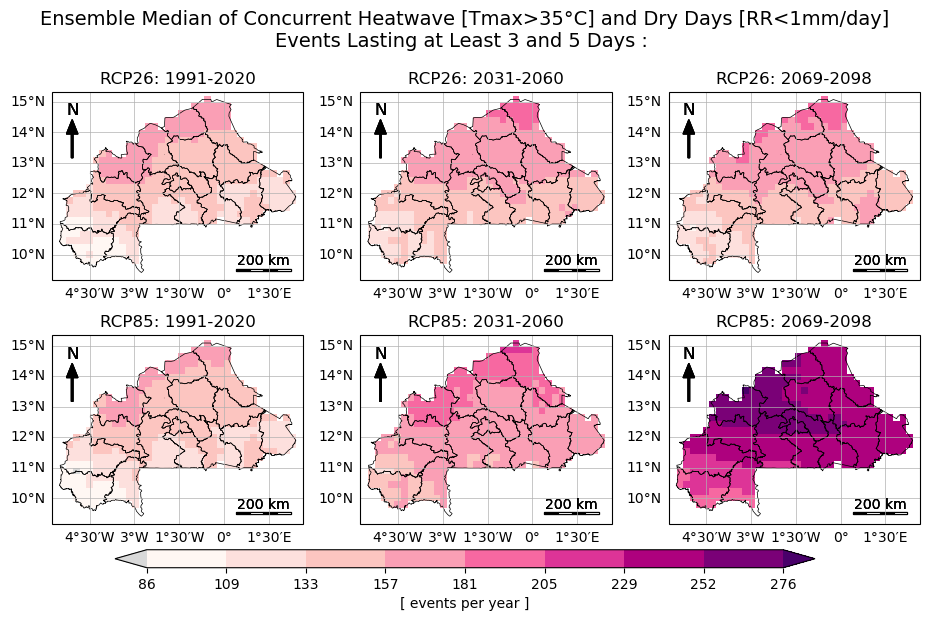

In [10]:
# Recalculate levels based on masked data
level_steps = min_max_levels(sims_rcp26_masked, sims_rcp85_masked, var)


# Now plot the absolute values
plot_absolut(
    sims_rcp26_masked,
    sims_rcp85_masked,
    level_steps, 
    color_steps,    
    plot_dir,
    title=title,
    var=var,
    westafrica=True,
    shapefile=shpfile_country,
    country=country,
    user_dpi=1200,
    rows=2, 
    columns=3,
    fancy=True,
    row_gap=-0.05,
    wspace=0.25
)

# save plot to better file name and do not over right old plots
src=os.path.join(plot_dir,'ev_coin_sdu_median_absolut_'+country+'_1200.png')
print ('src: ',src)
dst=os.path.join(plot_dir,var_pattern+'_median_absolut_'+country+'_1200.png')
print(f"Moving {src} -> {dst}")
shutil.move(src, dst)



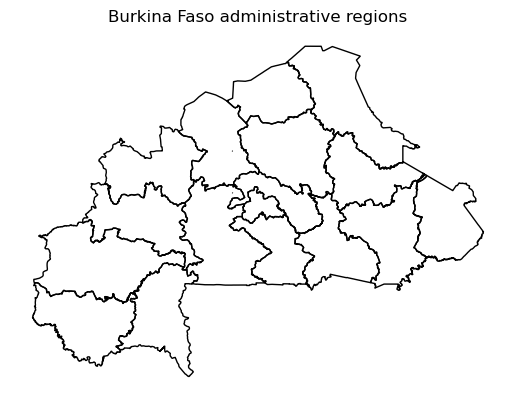

In [12]:
# Plot the preloaded Burkina Faso shapefile
ax = shpfile_country.plot(edgecolor='black', facecolor='none')
ax.set_title('Burkina Faso administrative regions')
ax.set_axis_off()
plt.show()

In [14]:
# Add a dynamic scale bar (in km) to the existing shapefile plot (ax)

def _nice_length_km(target_km):
    # pick a nice rounded length close to 20% of map width
    candidates = [10, 25, 50, 100, 150, 200, 300, 500, 1000]
    for c in candidates:
        if c >= target_km:
            return c
    return candidates[-1]

def add_scalebar(ax, geom=None, location='lower left', segments=4, pad_frac=0.05, height_frac=0.01, font_size=10):
    # Representative latitude for km-per-degree conversion
    if geom is not None:
        lat_ref = float(geom.centroid.y)
    else:
        y0, y1 = ax.get_ylim()
        lat_ref = (y0 + y1) / 2.0

    # Approx km per degree of longitude at given latitude
    km_per_deg_lon = 111.32 * np.cos(np.deg2rad(lat_ref))

    # Determine bar length ~ 20% of map width, rounded to a nice value
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    width_deg = x1 - x0
    width_km = max(1e-6, width_deg * km_per_deg_lon)
    length_km = _nice_length_km(width_km * 0.2)
    length_deg = length_km / km_per_deg_lon

    # Bar placement
    pad_x = pad_frac * width_deg
    pad_y = pad_frac * (y1 - y0)
    bar_height = height_frac * (y1 - y0)

    if location == 'lower left':
        bx0 = x0 + pad_x
        by0 = y0 + pad_y
    elif location == 'lower right':
        bx0 = x1 - pad_x - length_deg
        by0 = y0 + pad_y
    elif location == 'upper left':
        bx0 = x0 + pad_x
        by0 = y1 - pad_y - bar_height
    elif location == 'upper right':
        bx0 = x1 - pad_x - length_deg
        by0 = y1 - pad_y - bar_height
    else:
        bx0 = x0 + pad_x
        by0 = y0 + pad_y

    # Draw alternating black/white segments
    seg_width = length_deg / max(1, segments)
    for i in range(segments):
        rect = mpl.patches.Rectangle(
            (bx0 + i * seg_width, by0),
            seg_width,
            bar_height,
            facecolor=('black' if i % 2 == 0 else 'white'),
            edgecolor='black',
            linewidth=0.8
        )
        ax.add_patch(rect)

    # Label
    ax.text(
        bx0 + length_deg / 2.0,
        by0 + bar_height * 1.5,
        f'{int(length_km)} km',
        ha='center', va='bottom',
        fontsize=font_size
    )

# Compute Burkina Faso union geometry from the already loaded shapefile
union_geom = shpfile_country.geometry.unary_union

# Use the existing ax and Burkina Faso geometry union to add a scale bar
add_scalebar(ax, geom=union_geom, location='lower left', segments=4)

/tmp/ipykernel_1004455/1156274220.py:74: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  union_geom = shpfile_country.geometry.unary_union


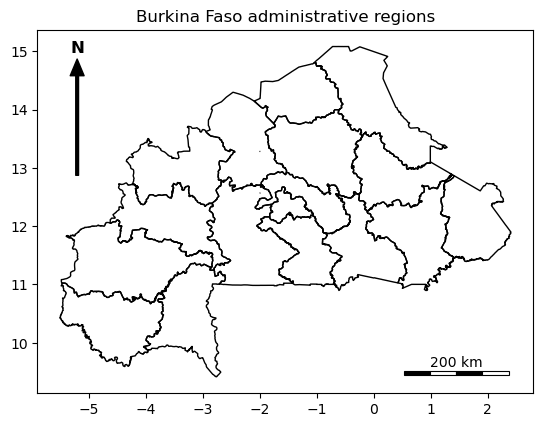

In [15]:
ax = shpfile_country.plot(edgecolor='black', facecolor='none')
ax.set_title('Burkina Faso administrative regions')
# Add a North arrow to the existing shapefile plot (ax)
arrowprops = dict(facecolor='black', edgecolor='black', width=2, headwidth=10, headlength=12)
# Arrow pointing up in axes coordinates
ax.annotate('', xy=(0.08, 0.92), xytext=(0.08, 0.60), xycoords='axes fraction', arrowprops=arrowprops)
# Label "N" above the arrow
ax.text(0.08, 0.93, 'N', transform=ax.transAxes, ha='center', va='bottom', fontsize=12, fontweight='bold')
add_scalebar(ax, geom=union_geom, location='lower right', segments=4)
plt.show()